# Aula 7.5 — Exercício guiado
## Mesmo orçamento, três estratégias: Grid Search, Random Search e Optuna

**Objetivo:** comparar três estratégias de otimização de hiperparâmetros de um `GradientBoostingClassifier`, mantendo o mesmo dataset, a mesma divisão treino/teste, os mesmos folds de validação cruzada e a mesma métrica (`ROC AUC`).

O roteiro acompanha as etapas práticas das páginas 43–55 do PDF da Aula 7.5.

**Regra importante:** o conjunto de teste fica reservado até a avaliação final. Nenhuma busca ou decisão de hiperparâmetros pode utilizar `X_test` ou `y_test`.

### O que será comparado

- **Grid Search:** 12 configurações predefinidas × 3 folds.
- **Random Search:** 12 configurações amostradas × 3 folds.
- **Optuna (TPE + MedianPruner):** até 12 trials, com avaliação progressiva em 25, 50, 75, 100 e 150 árvores.

A contagem de configurações não é a mesma coisa que custo computacional efetivo: o Optuna pode interromper trials antes de chegar a 150 árvores.

### Instalação das bibliotecas

Se estiver usando Jupyter ou Google Colab e algum pacote não estiver instalado, execute em uma célula:

```python
%pip install numpy pandas matplotlib scipy scikit-learn optuna
```

No terminal do Windows/VS Code, use: `python -m pip install numpy pandas matplotlib scipy scikit-learn optuna`.

## Etapa 1 — Imports e versões

Vamos importar as ferramentas para criar o dataset, dividir os dados, executar as buscas, medir tempo e avaliar os modelos. Também registraremos as versões, pois algumas APIs podem variar entre instalações.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from optuna.trial import TrialState
from scipy.stats import randint, loguniform

from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix
)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Optuna:", optuna.__version__)
import scipy, sklearn
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.3.5
Pandas: 2.2.3
Optuna: 4.8.0
SciPy: 1.17.0
Scikit-learn: 1.8.0


## Etapa 2 — Criar o dataset

Usaremos `make_classification`, que gera dados sintéticos reproduzíveis. O conjunto terá **1.800 amostras e 16 características**: 8 informativas, 4 redundantes e 4 restantes sem informação diretamente especificada como informativa ou redundante.

A proporção alvo é de 55% para a classe 0 e 45% para a classe 1, com 2% de ruído nos rótulos.

In [2]:
X, y = make_classification(
    n_samples=1800,
    n_features=16,
    n_informative=8,
    n_redundant=4,
    n_repeated=0,
    n_classes=2,
    weights=[0.55, 0.45],
    flip_y=0.02,
    class_sep=1.0,
    random_state=42
)

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Classes e contagens:", np.unique(y, return_counts=True))

Formato de X: (1800, 16)
Formato de y: (1800,)
Classes e contagens: (array([0, 1]), array([994, 806]))


## Etapa 3 — Explorar os dados

Vamos criar uma tabela com nomes `x0` a `x15`, verificar as primeiras linhas, estatísticas descritivas e a distribuição das classes.

Primeiras linhas:
         x0        x1        x2        x3        x4        x5        x6        x7        x8        x9       x10       x11       x12       x13       x14       x15  classe
0  1.217584  4.415994  1.387425  1.885603 -1.300577  0.382351  0.716784  0.139440 -0.582640 -1.610350 -0.372311  0.452303  1.721163 -0.873513 -1.590089 -1.837639       1
1  0.837133 -5.454840 -2.328806  2.330211  0.611884 -2.152620 -1.008074 -2.269772 -0.697064 -4.020287  1.020508  3.353297  1.480939  5.141032 -0.230980  0.487489       1
2  0.087591 -1.198248 -0.863188  2.112929  0.332905 -0.565000  0.524057 -0.534707 -1.776887  0.199177  1.410266  1.785070 -0.004564 -0.129327 -0.279515 -0.240919       0
3 -0.449704 -2.655033 -0.506532  1.614390  2.564391 -1.252938 -1.688111  0.868028  1.101401  1.984753 -0.445263  2.998006  3.270003  0.638245  1.134723 -0.761933       1
4  3.489748  6.386206 -1.268014  0.865506 -3.950049  2.353103  1.053695 -1.914108 -1.704564 -2.090938 -0.946018 -2.532225 -0.088138 

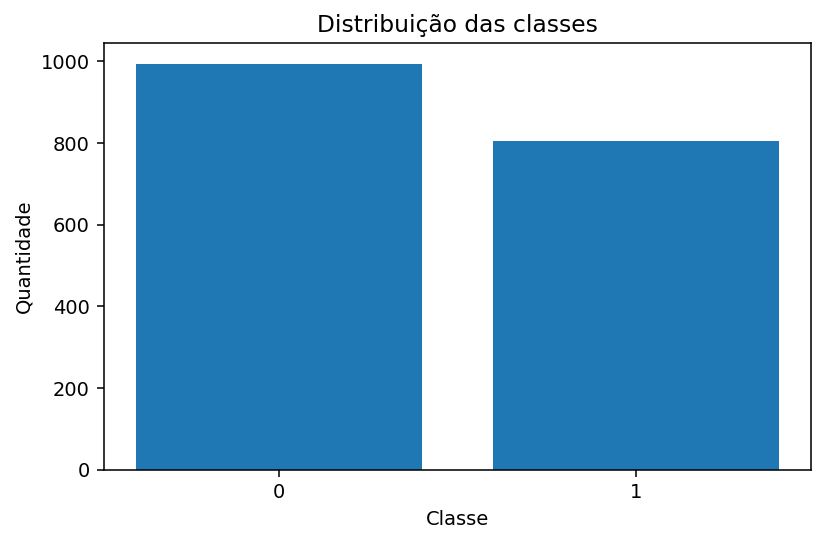

In [3]:
df = pd.DataFrame(X, columns=[f"x{i}" for i in range(16)])
df["classe"] = y

print("Primeiras linhas:")
print(df.head())
print("\nEstatísticas descritivas:")
print(df.describe())
print("\nProporção das classes:")
print(df["classe"].value_counts(normalize=True).sort_index())

contagens = df["classe"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(contagens.index.astype(str), contagens.values)
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

## Etapa 4 — Separar treino e teste

O split será estratificado e reservado: **80% para treinamento (1.440 amostras) e 20% para teste (360 amostras)**. O teste só será utilizado na etapa de avaliação final.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Treino:", X_train.shape, y_train.shape)
print("Teste:", X_test.shape, y_test.shape)
print("Distribuição no treino:", np.unique(y_train, return_counts=True))
print("Distribuição no teste:", np.unique(y_test, return_counts=True))

Treino: (1440, 16) (1440,)
Teste: (360, 16) (360,)
Distribuição no treino: (array([0, 1]), array([795, 645]))
Distribuição no teste: (array([0, 1]), array([199, 161]))


## Etapas 5 e 6 — Mesmos folds e baseline

Usaremos `StratifiedKFold` com três divisões, embaralhamento e semente 42. A lista `splits` será reutilizada pelas três estratégias.

Como referência inicial, calcularemos a ROC AUC de um `GradientBoostingClassifier` com 150 estimadores, sem otimização.

In [5]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)
splits = list(cv.split(X_train, y_train))

print("Número de folds:", len(splits))
for i, (idx_tr, idx_va) in enumerate(splits, start=1):
    print(f"Fold {i}: ajuste={len(idx_tr)}, validação={len(idx_va)}")

baseline = GradientBoostingClassifier(
    n_estimators=150,
    random_state=42
)
auc_baseline = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=splits,
    scoring="roc_auc",
    n_jobs=1
).mean()
print(f"ROC AUC média do baseline: {auc_baseline:.4f}")

Número de folds: 3
Fold 1: ajuste=960, validação=480
Fold 2: ajuste=960, validação=480
Fold 3: ajuste=960, validação=480
ROC AUC média do baseline: 0.9285


## Etapas 7 e 8 — Grid Search

A grade possui:

- `max_depth`: 1, 2 ou 3;
- `learning_rate`: 0,03 ou 0,10;
- `min_samples_leaf`: 1 ou 5.

Logo, são `3 × 2 × 2 = 12` configurações. Com três folds, teremos **36 ajustes de modelos**, cada um com 150 árvores. Usamos `refit=False` para não realizar automaticamente um ajuste adicional ao final da busca.

In [6]:
param_grid = {
    "max_depth": [1, 2, 3],
    "learning_rate": [0.03, 0.10],
    "min_samples_leaf": [1, 5]
}

n_config_grid = int(np.prod([len(v) for v in param_grid.values()]))
print("Configurações Grid:", n_config_grid)
print("Ajustes de modelo (configurações × folds):", n_config_grid * len(splits))

modelo_base = GradientBoostingClassifier(
    n_estimators=150,
    random_state=42
)

grid = GridSearchCV(
    estimator=modelo_base,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=splits,
    n_jobs=1,
    refit=False,
    return_train_score=True,
    error_score="raise"
)

inicio = time.perf_counter()
grid.fit(X_train, y_train)
tempo_grid = time.perf_counter() - inicio

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor ROC AUC média (CV): {grid.best_score_:.4f}")
print(f"Tempo de busca: {tempo_grid:.2f} s")

Configurações Grid: 12
Ajustes de modelo (configurações × folds): 36
Melhores parâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1}
Melhor ROC AUC média (CV): 0.9285
Tempo de busca: 16.15 s


### Inspecionar os resultados do Grid Search

`cv_results_` contém resultados por configuração, incluindo médias e desvios dos scores de treino e validação, ranking e tempo de ajuste.

In [7]:
resultados_grid = pd.DataFrame(grid.cv_results_)
colunas_grid = [
    "params", "mean_test_score", "std_test_score",
    "mean_train_score", "rank_test_score", "mean_fit_time"
]
print(resultados_grid[colunas_grid].sort_values("rank_test_score").to_string(index=False))

                                                        params  mean_test_score  std_test_score  mean_train_score  rank_test_score  mean_fit_time
 {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1}         0.928460        0.006188          0.999193                1       0.613099
 {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 5}         0.924803        0.008756          0.998812                2       0.709611
{'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 1}         0.909112        0.003982          0.976286                3       0.594079
{'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 5}         0.907930        0.005295          0.974265                4       0.658605
 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 5}         0.907808        0.012555          0.979223                5       0.434558
 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1}         0.906790        0.016303          0.979933           

## Etapas 9 e 10 — Random Search

O Random Search fará 12 tentativas amostradas das distribuições:

- `randint(1, 4)`: inteiros 1, 2 ou 3;
- `loguniform(0.02, 0.15)`: taxa de aprendizado contínua em escala logarítmica;
- `randint(1, 6)`: inteiros 1 a 5.

Com 12 tentativas e três folds, teremos também 36 ajustes de modelos com 150 árvores.

In [8]:
param_distributions = {
    "max_depth": randint(1, 4),
    "learning_rate": loguniform(0.02, 0.15),
    "min_samples_leaf": randint(1, 6)
}

random_search = RandomizedSearchCV(
    estimator=modelo_base,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="roc_auc",
    cv=splits,
    random_state=42,
    n_jobs=1,
    refit=False,
    return_train_score=True,
    error_score="raise"
)

inicio = time.perf_counter()
random_search.fit(X_train, y_train)
tempo_random = time.perf_counter() - inicio

print("Melhores parâmetros:", random_search.best_params_)
print(f"Melhor ROC AUC média (CV): {random_search.best_score_:.4f}")
print(f"Tempo de busca: {tempo_random:.2f} s")

Melhores parâmetros: {'learning_rate': 0.14227406173477572, 'max_depth': 3, 'min_samples_leaf': 3}
Melhor ROC AUC média (CV): 0.9309
Tempo de busca: 16.10 s


### Inspecionar as configurações sorteadas

A busca aleatória não precisa escolher os mesmos pontos da grade. Ela sorteia valores conforme as distribuições declaradas.

In [9]:
resultados_random = pd.DataFrame(random_search.cv_results_)
colunas_random = [
    "params", "mean_test_score", "std_test_score",
    "mean_train_score", "rank_test_score", "mean_fit_time"
]
print(resultados_random[colunas_random].sort_values("rank_test_score").to_string(index=False))

                                                                        params  mean_test_score  std_test_score  mean_train_score  rank_test_score  mean_fit_time
 {'learning_rate': 0.14227406173477572, 'max_depth': 3, 'min_samples_leaf': 3}         0.930870        0.005048          0.999981                1       0.675062
 {'learning_rate': 0.11454791487656053, 'max_depth': 3, 'min_samples_leaf': 5}         0.926131        0.007984          0.999631                2       0.640769
 {'learning_rate': 0.11311769174491627, 'max_depth': 3, 'min_samples_leaf': 5}         0.925067        0.006249          0.999588                3       0.619513
  {'learning_rate': 0.1411758906434134, 'max_depth': 2, 'min_samples_leaf': 2}         0.916057        0.012151          0.989978                4       0.457033
{'learning_rate': 0.027386388058464273, 'max_depth': 3, 'min_samples_leaf': 3}         0.907462        0.004047          0.972715                5       0.608275
 {'learning_rate': 0.0686181

## Etapas 11 e 12 — Configurar o sampler e o pruner do Optuna

- **Sampler (TPE):** propõe os hiperparâmetros de cada trial. Com `n_startup_trials=5`, os cinco primeiros trials são amostras iniciais; depois o TPE passa a utilizar o histórico.
- **Pruner (MedianPruner):** avalia resultados intermediários e pode interromper trials pouco promissores. O aquecimento é de 50 árvores, com verificações a cada 25 passos e pelo menos três trials anteriores para comparação.

In [10]:
sampler = optuna.samplers.TPESampler(
    seed=42,
    n_startup_trials=5
)

pruner = optuna.pruners.MedianPruner(
    n_startup_trials=5,
    n_warmup_steps=50,
    interval_steps=25,
    n_min_trials=3
)

CHECKPOINTS = [25, 50, 75, 100, 150]
N_FOLDS = len(splits)
print("Checkpoints:", CHECKPOINTS)
print("Folds usados em cada checkpoint:", N_FOLDS)

Checkpoints: [25, 50, 75, 100, 150]
Folds usados em cada checkpoint: 3


## Etapa 13 — Função objetivo com treinamento progressivo, report e pruning

Para cada trial, criaremos um modelo independente para cada fold. Todos começam com 25 árvores e usam `warm_start=True`. Nos checkpoints seguintes, aumentamos `n_estimators` e acrescentamos árvores sem reiniciar o ensemble.

Em cada checkpoint:

1. Treinamos/atualizamos os três modelos;
2. calculamos ROC AUC na validação de cada fold;
3. tiramos a média dos três folds;
4. reportamos essa média ao Optuna;
5. permitimos ao pruner interromper o trial, exceto no checkpoint final.

Assim, o valor reportado em cada etapa é comparável porque os três folds chegam ao mesmo número de árvores antes da média.

In [11]:
def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 1, 3),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.15, log=True
        ),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5)
    }

    modelos = [
        GradientBoostingClassifier(
            n_estimators=CHECKPOINTS[0],
            warm_start=True,
            random_state=42,
            **params
        )
        for _ in splits
    ]

    media_auc = None

    for checkpoint in CHECKPOINTS:
        aucs = []

        for modelo, (idx_tr, idx_va) in zip(modelos, splits):
            modelo.set_params(n_estimators=checkpoint)
            modelo.fit(X_train[idx_tr], y_train[idx_tr])

            probabilidades = modelo.predict_proba(X_train[idx_va])[:, 1]
            aucs.append(roc_auc_score(y_train[idx_va], probabilidades))

        media_auc = float(np.mean(aucs))
        trial.set_user_attr("ultimo_checkpoint", checkpoint)
        trial.report(media_auc, step=checkpoint)

        if checkpoint < CHECKPOINTS[-1] and trial.should_prune():
            raise optuna.TrialPruned()

    return media_auc

print("Função objetivo definida.")

Função objetivo definida.


## Etapas 14 e 15 — Criar o Study e executar até 12 trials

O objetivo é maximizar ROC AUC. A busca tem limite de 12 trials; o pruning pode interromper alguns antes de 150 árvores, conforme os resultados intermediários.

In [12]:
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    pruner=pruner
)

inicio = time.perf_counter()
study.optimize(
    objective,
    n_trials=12,
    n_jobs=1,
    show_progress_bar=True
)
tempo_optuna = time.perf_counter() - inicio

completos = study.get_trials(states=[TrialState.COMPLETE])
podados = study.get_trials(states=[TrialState.PRUNED])

print("Melhores parâmetros:", study.best_params)
print(f"Melhor ROC AUC média (CV): {study.best_value:.4f}")
print("Trials completos:", len(completos))
print("Trials interrompidos:", len(podados))
print(f"Tempo de busca: {tempo_optuna:.2f} s")

Melhores parâmetros: {'max_depth': 3, 'learning_rate': 0.0433793244812684, 'min_samples_leaf': 2}
Melhor ROC AUC média (CV): 0.9168
Trials completos: 10
Trials interrompidos: 2
Tempo de busca: 18.92 s


### Consultar o histórico dos trials

Cada linha mostra uma tentativa, seu estado, score (quando concluída), parâmetros e último checkpoint alcançado. Trials interrompidos podem não ter um valor final em `value`, porque não chegaram ao checkpoint 150.

In [13]:
linhas_trials = []
for t in study.trials:
    linhas_trials.append({
        "trial": t.number,
        "estado": t.state.name,
        "ROC_AUC_final": t.value,
        "ultimo_checkpoint": t.user_attrs.get("ultimo_checkpoint", 0),
        **t.params
    })

df_trials = pd.DataFrame(linhas_trials)
print(df_trials.to_string(index=False))

 trial   estado  ROC_AUC_final  ultimo_checkpoint  max_depth  learning_rate  min_samples_leaf
     0 COMPLETE       0.912851                150          2       0.135820                 4
     1 COMPLETE       0.877300                150          2       0.027388                 1
     2 COMPLETE       0.852456                150          1       0.114548                 4
     3 COMPLETE       0.900641                150          3       0.020847                 5
     4 COMPLETE       0.909604                150          3       0.030679                 1
     5   PRUNED       0.834044                 50          1       0.131021                 3
     6 COMPLETE       0.899851                150          2       0.062514                 5
     7 COMPLETE       0.899845                150          2       0.070330                 3
     8   PRUNED       0.826912                 50          1       0.093425                 4
     9 COMPLETE       0.915928                150          3

## Etapa 16 — Comparar orçamento, trabalho e tempo

Grid e Random Search fazem 12 configurações × 3 folds × 150 árvores = 5.400 estimadores-base cada. Para o Optuna, somamos o último checkpoint de cada trial multiplicado pelo número de folds. Como os modelos usam `warm_start=True`, esse total aproxima as árvores efetivamente acrescentadas.

Essa contagem é uma aproximação do trabalho: profundidade, divisões e custo por árvore também influenciam o tempo real.

In [14]:
arvores_grid = 12 * N_FOLDS * 150
arvores_random = 12 * N_FOLDS * 150
arvores_optuna = sum(
    t.user_attrs.get("ultimo_checkpoint", 0) * N_FOLDS
    for t in study.trials
)

orcamento = pd.DataFrame({
    "Estratégia": ["Grid Search", "Random Search", "Optuna"],
    "Configurações/trials": [12, 12, len(study.trials)],
    "Trials interrompidos": [0, 0, len(podados)],
    "Árvores-base (aprox.)": [arvores_grid, arvores_random, arvores_optuna],
    "Tempo de busca (s)": [tempo_grid, tempo_random, tempo_optuna]
})
print(orcamento.to_string(index=False))

   Estratégia  Configurações/trials  Trials interrompidos  Árvores-base (aprox.)  Tempo de busca (s)
  Grid Search                    12                     0                   5400           16.150258
Random Search                    12                     0                   5400           16.097171
       Optuna                    12                     2                   4800           18.916054


## Etapas 17 e 18 — Selecionar parâmetros e treinar modelos finais

Vamos recuperar a melhor configuração de cada estratégia e treinar três modelos finais com **150 estimadores** sobre todo o conjunto de treinamento (`X_train`, `y_train`). Isso mantém o protocolo do PDF: o teste continua reservado até a avaliação seguinte.

O tempo de ajuste final será medido separadamente do tempo de busca.

In [15]:
melhores = {
    "Grid Search": grid.best_params_,
    "Random Search": random_search.best_params_,
    "Optuna (TPE + pruning)": study.best_params
}

scores_cv = {
    "Grid Search": grid.best_score_,
    "Random Search": random_search.best_score_,
    "Optuna (TPE + pruning)": study.best_value
}

tempos_busca = {
    "Grid Search": tempo_grid,
    "Random Search": tempo_random,
    "Optuna (TPE + pruning)": tempo_optuna
}

modelos_finais = {}
tempos_fit_final = {}

for nome, params in melhores.items():
    modelo_final = GradientBoostingClassifier(
        n_estimators=150,
        random_state=42,
        **params
    )
    inicio = time.perf_counter()
    modelo_final.fit(X_train, y_train)
    tempos_fit_final[nome] = time.perf_counter() - inicio
    modelos_finais[nome] = modelo_final

print("Configurações selecionadas:")
for nome, params in melhores.items():
    print(f"{nome}: {params}")
print("\nTempos de ajuste final:", tempos_fit_final)

Configurações selecionadas:
Grid Search: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1}
Random Search: {'learning_rate': 0.14227406173477572, 'max_depth': 3, 'min_samples_leaf': 3}
Optuna (TPE + pruning): {'max_depth': 3, 'learning_rate': 0.0433793244812684, 'min_samples_leaf': 2}

Tempos de ajuste final: {'Grid Search': 1.122, 'Random Search': 1.093, 'Optuna (TPE + pruning)': 1.073}


## Etapa 19 — Avaliar uma única vez no conjunto de teste

Agora que todas as escolhas foram feitas, usamos o teste. Para cada modelo calculamos:

- ROC AUC: qualidade da ordenação dos escores;
- acurácia: proporção de classes corretas com limiar 0,5;
- F1: equilíbrio entre precisão e recall;
- Log Loss: qualidade das probabilidades;
- matriz de confusão.

Todos recebem exatamente `X_test` e `y_test`.

In [16]:
resultados_teste = {}
matrizes_confusao = {}

for nome, modelo in modelos_finais.items():
    proba = modelo.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    resultados_teste[nome] = {
        "ROC AUC teste": roc_auc_score(y_test, proba),
        "Acurácia": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Log Loss": log_loss(y_test, proba, labels=[0, 1])
    }
    matrizes_confusao[nome] = confusion_matrix(y_test, pred, labels=[0, 1])

    print(f"\n{nome}")
    for metrica, valor in resultados_teste[nome].items():
        print(f"{metrica}: {valor:.4f}")
    print("Matriz de confusão (linhas = real; colunas = previsto):")
    print(matrizes_confusao[nome])


Grid Search
ROC AUC teste: 0.9488
Acurácia: 0.8750
F1: 0.8589
Log Loss: 0.2992
Matriz de confusão (linhas = real; colunas = previsto):
[[178  21]
 [ 24 137]]

Random Search
ROC AUC teste: 0.9561
Acurácia: 0.8750
F1: 0.8607
Log Loss: 0.2729
Matriz de confusão (linhas = real; colunas = previsto):
[[176  23]
 [ 22 139]]

Optuna (TPE + pruning)
ROC AUC teste: 0.9380
Acurácia: 0.8750
F1: 0.8571
Log Loss: 0.3435
Matriz de confusão (linhas = real; colunas = previsto):
[[180  19]
 [ 26 135]]


## Etapas 20 a 22 — Tabela final e conclusão

A tabela reúne a melhor ROC AUC de validação cruzada e as métricas de teste. Os números são calculados pelo próprio notebook; não devem ser preenchidos manualmente nem copiados de outra execução.

In [17]:
linhas = []
for nome in melhores:
    linhas.append({
        "Estratégia": nome,
        "AUC CV": scores_cv[nome],
        "AUC teste": resultados_teste[nome]["ROC AUC teste"],
        "Acurácia": resultados_teste[nome]["Acurácia"],
        "F1": resultados_teste[nome]["F1"],
        "Log Loss": resultados_teste[nome]["Log Loss"],
        "Busca (s)": tempos_busca[nome],
        "Ajuste final (s)": tempos_fit_final[nome]
    })

tabela_final = pd.DataFrame(linhas).set_index("Estratégia")
print(tabela_final.round(4).to_string())

                        AUC CV  AUC teste  Acurácia      F1  Log Loss  Busca (s)  Ajuste final (s)
Estratégia                                                                                        
Grid Search             0.9285     0.9488     0.875  0.8589    0.2992    16.1503            1.1220
Random Search           0.9309     0.9561     0.875  0.8607    0.2729    16.0972            1.0930
Optuna (TPE + pruning)  0.9168     0.9380     0.875  0.8571    0.3435    18.9161            1.0733


### Gráfico 1 — ROC AUC no teste

Compare o desempenho final dos modelos no mesmo conjunto de teste.

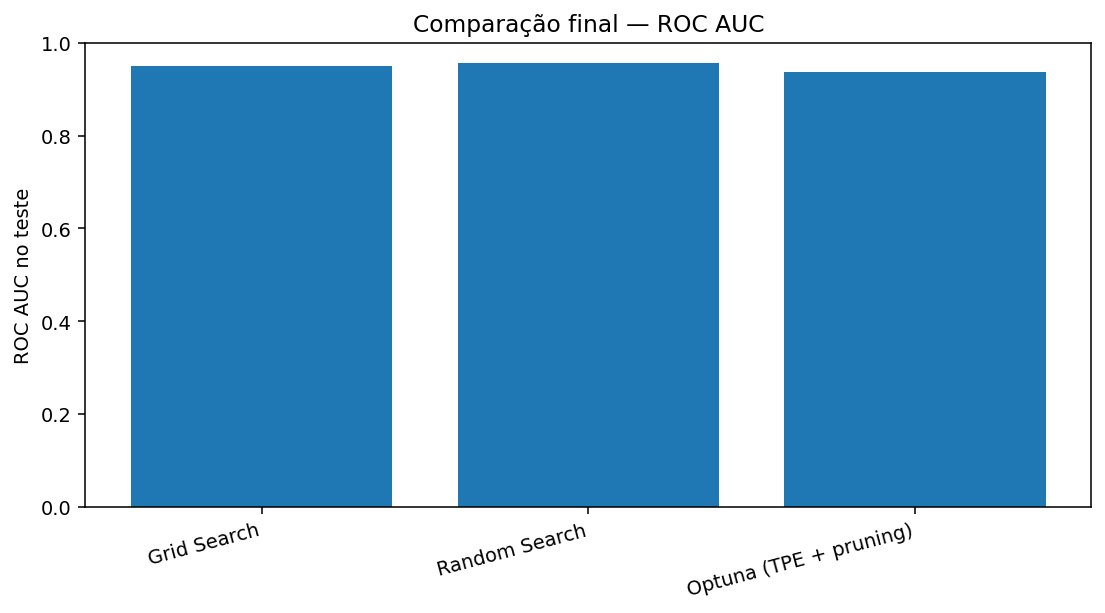

In [18]:
plt.figure(figsize=(8, 4.5))
plt.bar(tabela_final.index, tabela_final["AUC teste"])
plt.ylabel("ROC AUC no teste")
plt.title("Comparação final — ROC AUC")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Gráfico 2 — Tempo de busca

O tempo foi medido neste ambiente de execução. Ele pode variar com hardware, sistema operacional, carga da máquina e versões das bibliotecas.

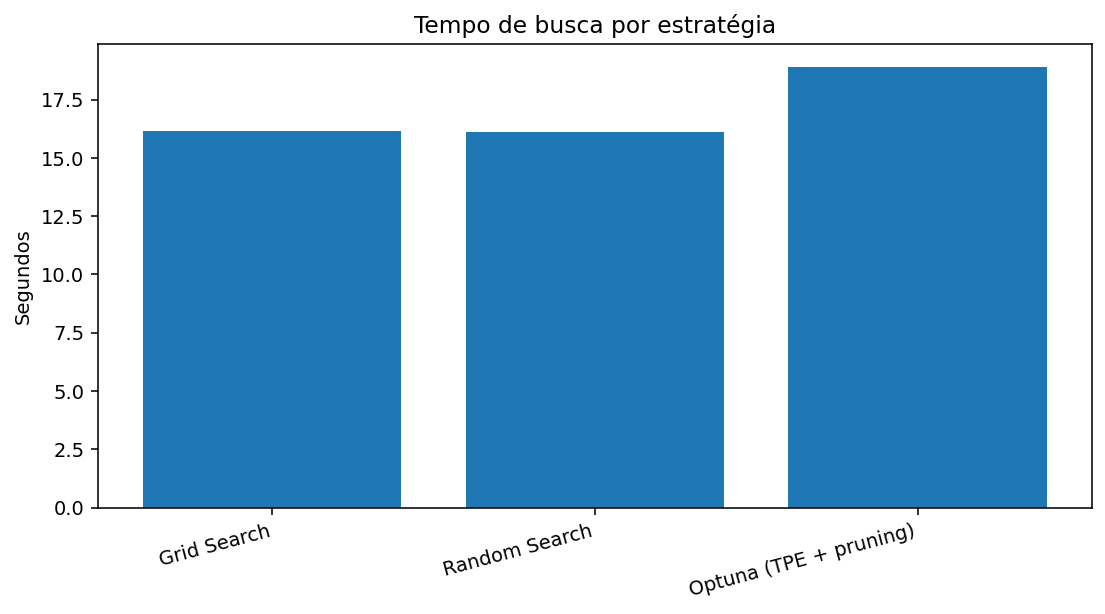

In [19]:
plt.figure(figsize=(8, 4.5))
plt.bar(tabela_final.index, tabela_final["Busca (s)"])
plt.ylabel("Segundos")
plt.title("Tempo de busca por estratégia")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Gráfico 3 — Trials do Optuna

Os pontos mostram a métrica intermediária final reportada por cada trial. Trials interrompidos são identificados pelo estado e pelo último checkpoint; não possuem necessariamente um score final em `t.value`.

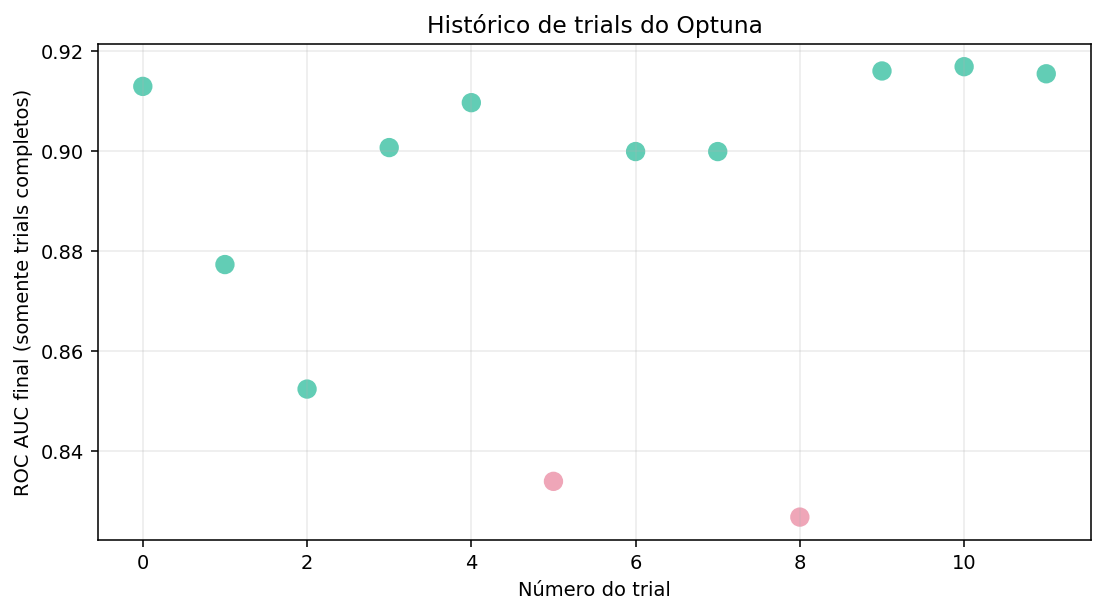

Legenda: verde-menta = completo; rosa = interrompido.


In [20]:
trial_nums = [t.number for t in study.trials]
trial_scores = [np.nan if t.value is None else t.value for t in study.trials]
trial_colors = ["#EFA6B8" if t.state == TrialState.PRUNED else "#62CDB5" for t in study.trials]

plt.figure(figsize=(8, 4.5))
plt.scatter(trial_nums, trial_scores, c=trial_colors, s=80)
plt.xlabel("Número do trial")
plt.ylabel("ROC AUC final (somente trials completos)")
plt.title("Histórico de trials do Optuna")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Legenda: verde-menta = completo; rosa = interrompido.")

### Gráfico 4 — Matrizes de confusão

Uma matriz por estratégia. Linhas representam a classe real e colunas a classe prevista.

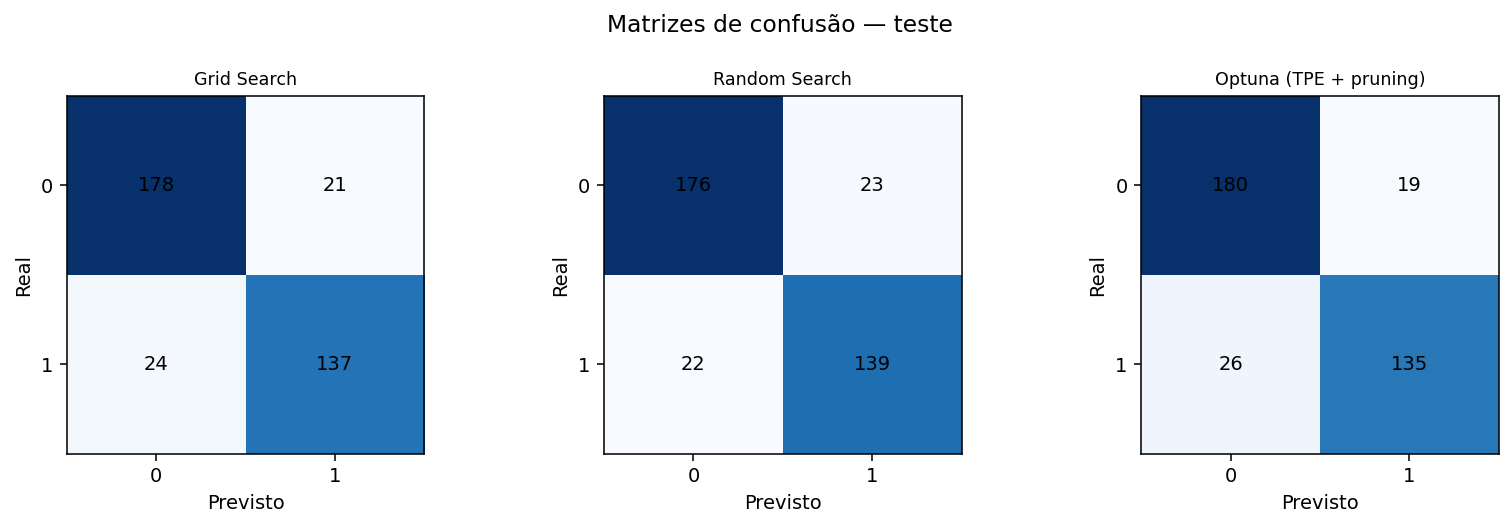

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (nome, cm) in zip(axes, matrizes_confusao.items()):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(nome, fontsize=9)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    for (i, j), valor in np.ndenumerate(cm):
        ax.text(j, i, str(valor), ha="center", va="center")
fig.suptitle("Matrizes de confusão — teste")
plt.tight_layout()
plt.show()

## Interpretação dos resultados

Responda com base nos números produzidos acima:

1. Qual estratégia teve a melhor ROC AUC na validação?
2. Qual teve a melhor ROC AUC no teste?
3. A estratégia com melhor validação também foi a melhor no teste?
4. Qual teve menor tempo de busca?
5. Quantos trials o Optuna interrompeu?
6. Quantas árvores-base foram estimadas para cada estratégia?
7. O Grid Search foi competitivo neste espaço de busca?
8. O Random Search encontrou valores diferentes dos pontos da grade?
9. O TPE utilizou o histórico para orientar novas tentativas depois dos trials iniciais?
10. O orçamento utilizado permite afirmar que uma estratégia é universalmente superior?

**Conclusão:** este é um experimento didático, com um único dataset e um espaço de busca pequeno. Ele permite comparar as estratégias sob um protocolo controlado, mas não comprova superioridade universal.

## Desafio final — Dataset Wine (atividade de casa)

O PDF propõe repetir o processo no dataset Wine do Scikit-learn:

- 178 amostras;
- 13 características químicas;
- 3 classes;
- métrica principal sugerida: acurácia.

Tarefas:

1. Carregar e explorar o dataset;
2. Dividir treinamento e teste;
3. Definir um espaço de busca adequado à classificação multiclasse;
4. Executar Grid Search;
5. Executar Random Search;
6. Executar Optuna;
7. Comparar resultados e tempos;
8. Avaliar os melhores modelos uma única vez no teste;
9. Explicar qual estratégia foi mais interessante neste experimento.

Mantenha as mesmas condições para as três estratégias e reserve o teste até o final.